## Summary: FAIL under the fixed rule

kmerseek with the mass-spec alphabet (massspec18, k = 8, chosen on the development split)
found the accepted source of 140 of 200 test de novo calls in its top five, and gave a
confident source to 4 of the 50 calls whose source had been removed. The rule asked for at
least 95% and at most 1%, so the test fails. The comparison (exact full-alphabet index plus
blastp-short, with the same full-alphabet check) did worse on both counts: 128 of 200 and 6
of 50. Neither workflow reaches the bar. About 40% of these de novo calls differ from the
accepted database-search peptide (rule 1), and some removed sources have a close paralog
left in the database (rule 2). These observations do not isolate the cause of every failure.

| Rule | Needed | kmerseek massspec18, k = 8 | Holds | Comparison C | Section |
|---|---|---|---|---|---|
| 1. accepted source in the top five, source-present calls | >= 95% | 140 of 200, 70.0% | no | 128 of 200, 64.0% | 4, 10 |
| 2. confident source, source-absent calls | <= 1% | 4 of 50, 8% | no | 6 of 50, 12% | 4, 10 |
| 3. median candidate-list length | <= 5 | 1 | yes | 1 | 5, 10 |
| 4a. recovery gain over C at the same false-assignment rate | >= 10 points | 70.0% against C's 53.5% at <= 8%: +16.5 points | yes | | 4, 10 |
| 4b. end-to-end speed-up at matched recovery | >= 5x | 125 s / 27 s = 4.6x (recovery matched) | no | | 6, 10 |

Compute for the whole notebook, every SLURM job included (section 9): 8.2 CPU-hours
allocated (cores x elapsed), 3.1 CPU-hours used; 1.2 hours elapsed summed over jobs, and
1 hour 29 minutes of wall clock from the first job's start (14:07) to the last job's end
(15:36) on 20 Oct 2026. The budget was two compute-days.

What the numbers say, in plain words:

- **kmerseek's lead over C is a threshold effect, not a better alphabet.** Both workflows
  give the accepted source the same check score whenever both send it to the check
  (section 4, scatter). kmerseek sends a median of 1 candidate per call, C a median of 221,
  so shuffled calls reach high scores less often under kmerseek and its 1%-of-shuffles
  threshold sits lower (62 against 66). Of the 15 calls only kmerseek recovers, 14 have the
  same score, 62 to 65, under both; the 15th (scan13458) was not among C's blastp-short hits.
  The 3 calls only C recovers share no exact 8-mer with their source.
- **Merging residues adds nothing here.** An exact 8-mer in massspec18 is the same as an
  exact 8-mer in the full alphabet once I is read as L and Q as K, which C also does. The two
  coarser alphabets, hsdm17 and sdm12, gave the same development recovery as massspec18 at
  k = 8 (70.0%) and were not sent to test (section 3).
- **The adjacent-pair shuffle is not a usable control for calls this short.** 566 of 1,250
  such shuffles of the test calls are the call itself, which is why both workflows assign
  34-36% of them (section 7). The composition shuffles behave: 1.0% (kmerseek) and 1.5% (C).
- **The fail clause is not what failed.** Reduction did not lengthen candidate lists (median
  1 sent to the check against C's 221), and the check costs kmerseek almost nothing (0.007 s).
  The test fails on rules 1 and 2. Rule 4 passes through the recovery-gain alternative
  (4a); the speed alternative (4b) fails.
- **Part of rule 1 is out of reach at k = 8.** 22 of the 200 source-present test calls are
  shorter than 8 residues and count as abstentions; 81 differ from the database-search peptide; this can reflect a de novo error or an
  incorrect accepted match.
- **A second reader recomputed every number** and found the FAIL holds (last section).

Decision: kmerseek is not pitched for source lookup of de novo peptide calls on the strength
of its alphabet. If a seed-and-check route is wanted, the same gain is available from an exact
full-alphabet 8-mer seed with I read as L and Q as K; that is untested here.

### Deviation from the pre-registration

One development setting, sdm12 at k = 4, was stopped after 40 minutes with 43 GB of search
output (about 5,000 candidate proteins per call), before any development score was read. It
is recorded in `STOPPED` in `nextflow-runs/fragment-source/bin/nb354.py` and in
`354_data/dev_choice.json`, and was not run or chosen. Nothing else changed.

### Inputs and runs

- Frozen data: `data/kill_tests/fragment_source/` (sha256 in `manifest.tsv`; downloads in
  `download_manifest.tsv`).
- Pipeline: `nextflow-runs/fragment-source/` (`make all` on Sherlock), kmerseek 4d7e27b
  (seanome/kmerseek PR 156), BLAST+ 2.16.0, parasail 1.3.4.
- Sherlock jobs: download 48678939, kmerseek build 48679601, freeze 48681774,
  development 48682102 (stopped) and 48689384, test 48690317, summary 48690319.
- Builder: `scripts/make_nb354.py`; pre-registration text `scripts/make_nb354_prereg.py`,
  committed in 3743f18a before any method ran on the frozen calls (a smoke test at 14:27
  searched 10 calls of an earlier freeze, none of the final 500, and computed no score).

# 354. Kill test: does a reduced-alphabet kmerseek index find the source protein of a short de novo peptide call?

**Question.** A mass spectrometer reads a peptide's sequence from its fragment masses
(de novo sequencing), with errors. Can a kmerseek index in a reduced alphabet, where
residues the spectrometer confuses share one letter, find the protein the peptide came from
better than the standard route: an exact index in the full 20-letter alphabet plus
blastp-short? The decision: if it fails, kmerseek is not pitched for proteomics source
lookup, and notebook 300's peptide work does not go on to a database-scale run.

**Prior, stated before any run: unfavourable.** Merging residues throws away the
differences that usually tell one source protein from another.

## Data (frozen under `data/kill_tests/fragment_source/`, with checksums)

- **Database:** UniProt human reference proteome UP000005640, release 2026_03 (file dated
  15 Sep 2026, downloaded 20 Oct 2026), 20,652 proteins, plus the cRAP contaminant list
  (The GPM, file dated 4 Mar 2019), 82 of its 116 entries; the other 34 are already in the
  human proteome with the same sequence. 20,734 proteins in all.
- **Peptide calls:** one completed analysis, PRIDE PXD005280 (Blank-Landeshammer et al.,
  *J Proteome Res* 16, no. 9 (2017): 3209-18, https://doi.org/10.1021/acs.jproteome.7b00198,
  as PRIDE lists it), run HeLa 1 (`qExHF01_02580`, a Q Exactive HF going by the file names). The calls are PEAKS
  de novo sequences, file `PEAKS_qExHF01_02580_de novo peptides.csv` inside `PEAKS.zip`,
  with PEAKS's per-residue local confidence and its ALC score (average local confidence)
  kept. PEAKS exported only calls with ALC >= 50%; nothing else is removed. Wrong and
  ambiguous calls stay in.
- **Accepted source:** the database search of the same spectrum, file
  `HeLa_1_qExHF01_02580.msf` (Proteome Discoverer 1.4: Mascot, MS Amanda and SEQUEST against
  a human UniProt file `U507_human_fw_2015_07_22.fasta` of 20,163 proteins; Percolator). A spectrum counts when every engine with a
  rank-1 match at Percolator confidence "High" (q < 0.01) gives the same peptide. Its
  accepted sources are all the proteins that peptide maps to, kept if the frozen database
  has them. This search never sees the de novo call. Both analyses still use the same spectrum,
  so their errors need not be statistically independent.
- 22,332 de novo calls have an accepted source in the database (joined to their PD spectrum
  on charge, precursor mass within 10 ppm and retention time within 0.02 min, because the two
  programs number spectra differently). **500**
  are drawn at random (seed 354).
- **Split by source protein:** calls that share an accepted protein form a group; groups go
  to development until it holds half the calls (seed 3540). 250 development, 250 test, no
  protein in both.
- **Source-absent set:** 50 of the 250 test calls (20%, seed 3541). Their 59 accepted
  proteins are removed from the database these 50 are searched against. The right answer
  for them is "abstain".
- **Shuffled controls:** 10 composition shuffles of each development call (2,500, used to
  set each method's confidence threshold) and, for each test call, 5 composition shuffles
  and 5 shuffles that keep every adjacent residue pair (seed 3542).

## The two workflows

Both get the same uncertainty information: I and L have the same mass, and Q and K differ
by 0.036 Da, so both pairs count as the same residue. PEAKS writes every I/L as L. The
per-residue local confidence is kept in the frozen table but given to neither workflow.

- **K, kmerseek** (seanome/kmerseek 4d7e27b, PR 156): index the database in the mass-spec
  alphabet `massspec18` (I = L, Q = K, the other 16 residues apart), search each call, take
  every protein kmerseek reports as a candidate (`--min-shared-kmers 1
  --max-query-pvalue 1 --extend-mismatch-penalty 0`, scaled 1). One k from {4, 5, 6, 7, 8,
  9}, chosen on development. A call shorter than k gets no candidates and counts as an
  abstention. At most one coarser alphabet that also merges I and L
  (`hsdm17` or `sdm12`) with its own k, chosen on development, goes to test only if it
  recovers more development calls than massspec18.
- **C, comparison:** an exact 5-mer index of the database in the full alphabet (I written as
  L, Q as K) that finds every protein holding the whole peptide, plus blastp-short (BLAST+
  2.16.0, `-task blastp-short -evalue 1000 -max_target_seqs 500`) against the same
  database. Its candidates are the union of the two.
- **The check, the same for both:** each candidate is aligned with the call in the full
  alphabet (Smith-Waterman, PAM30, gap open 9, extend 1, as blastp-short; parasail 1.3.4).
  Its score ranks the candidates; ties go by accession.
- **Confidence threshold:** for each method, the smallest score that at most 1% of the
  2,500 shuffled development calls reach with their best candidate. A call whose best
  candidate scores below it is an abstention. The candidate list is every candidate at or
  above it.
- **Runtime, end to end:** index build, search and check, on one CPU, for the 250 test
  calls against the full database; wall and CPU time.

## Pass rule (fixed before running; all must hold)

On the 200 source-present and 50 source-absent test calls, for a kmerseek setting frozen on
development:

1. At least 95% of source-present calls have an accepted source among the top five
   candidates at or above the threshold.
2. At most 1% of source-absent calls get a confident assignment (best candidate at or above
   the threshold). With 50 calls, that means none.
3. The median candidate-list length over source-present calls is at most five.
4. And one of:
   a. recovery (rule 1's fraction) at least 10 percentage points above workflow C's best
      recovery at a threshold whose false-assignment rate is no higher than kmerseek's; or
   b. at least fivefold lower end-to-end wall time than workflow C, with recovery no more
      than 2 points below C's ("matched recovery").

PASS if one frozen kmerseek setting meets all four. Otherwise FAIL. Also a fail, whatever
the four say: the reduced alphabet makes candidate lists longer without recovering more
real calls, or its speed gain disappears once the candidates are checked in the full
alphabet.

## How 354 differs from notebook 300

Notebook 300 (branch `olgabot/nb300-peptide-lookup`, not merged) asks whether kmerseek can
find the source of gut metaproteomics peptides in UHGP-90 with a decoy-measured error rate;
its Step 0 computes the smallest E-value one exact window can reach. 354 copies its
`massspec18` alphabet table and its counting estimate of chance matches (expected count =
starts x product of residue-class frequencies), but uses a human proteome plus
contaminants, real de novo calls whose sources were accepted by an independent database
search, and a 20% source-absent set that must be abstained on.

In [1]:
import csv
import json
import statistics
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(80)

FROZEN = Path("../data/kill_tests/fragment_source")
DATA = Path("354_data")
RES = DATA / "results"
FIG = Path("../figures")

calls = pl.read_csv(
    FROZEN / "calls.tsv", separator="\t", infer_schema_length=0
).with_columns(
    pl.col("length").cast(pl.Int64),
    pl.col("alc_percent").cast(pl.Float64),
    (pl.col("source_absent") == "True").alias("source_absent"),
    (pl.col("denovo_equals_db_search") == "True").alias("denovo_equals_db_search"),
)
freeze = json.loads((FROZEN / "freeze_summary.json").read_text())
choice = json.loads((DATA / "dev_choice.json").read_text())
dev = pl.read_csv(DATA / "dev_table.tsv", separator="\t")
m = json.loads((RES / "metrics.json").read_text())
curve = pl.read_csv(RES / "curve.tsv", separator="\t")
per_call = pl.read_csv(RES / "per_call.tsv", separator="\t", infer_schema_length=10_000)
runtime = pl.read_csv(RES / "runtime.tsv", separator="\t")
aln = pl.read_csv(RES / "alignments.tsv", separator="\t", infer_schema_length=10_000)
compute = pl.read_csv(RES / "compute.tsv", separator="\t")

KMERSEEK = [f"{s['alphabet']}_k{s['k']}" for s in choice["kmerseek_settings"]]
METHODS = KMERSEEK + ["comparison"]
LABEL = {"comparison": "C: exact index + blastp-short"}
for s in choice["kmerseek_settings"]:
    LABEL[f"{s['alphabet']}_k{s['k']}"] = f"K: kmerseek {s['alphabet']}, k = {s['k']}"
COLOUR = {"comparison": pf.OKABE_ITO["vermillion"]}
for name, c in zip(KMERSEEK, [pf.OKABE_ITO["blue"], pf.OKABE_ITO["bluish_green"]]):
    COLOUR[name] = c
TOOLS = (
    "Queries: 250 PEAKS de novo calls, PXD005280 HeLa run 1 (test split). Target: UniProt "
    "human reference proteome 2026_03 + cRAP, 20,734 proteins. Check: Smith-Waterman, PAM30."
)
print(json.dumps(freeze, indent=1))

{
 "seeds": {
  "draw": 354,
  "split": 3540,
  "absent": 3541,
  "shuffle": 3542
 },
 "n_peaks_calls_with_accepted_source_in_db": 22332,
 "n_spectra_with_agreed_high_confidence_psm": 24561,
 "peaks_to_pd_matching": {
  "ok": 22400,
  "no PD spectrum with an agreed match": 5338,
  "accepted source not in the frozen database": 68
 },
 "eligible_denovo_equals_db_search": 13965,
 "n_calls": 500,
 "n_dev": 250,
 "n_test": 250,
 "n_test_present": 200,
 "n_test_absent": 50,
 "n_proteins_removed_for_absent": 59,
 "db_full_proteins": 20734,
 "db_source_absent_proteins": 20675,
 "crap_entries": 116,
 "crap_kept": 82,
 "dev_test_protein_overlap": 0
}


## 1. The frozen calls

What the 500 calls look like before any method sees them: length, PEAKS's average local
confidence (ALC), and whether the de novo sequence equals the database-search peptide of
the same spectrum (I read as L, Q as K). A call that differs is a disagreement between the two sequence assignments; this alone
does not identify which assignment is wrong.

shape: (3, 6)
┌───────┬───────────────┬─────────┬──────────────────┬────────────────────┬──────────────────────────────────┐
│ split ┆ source_absent ┆ n_calls ┆ median_length_aa ┆ median_alc_percent ┆ fraction_denovo_equals_db_search │
│ ---   ┆ ---           ┆ ---     ┆ ---              ┆ ---                ┆ ---                              │
│ str   ┆ bool          ┆ u32     ┆ f64              ┆ f64                ┆ f64                              │
╞═══════╪═══════════════╪═════════╪══════════════════╪════════════════════╪══════════════════════════════════╡
│ dev   ┆ false         ┆ 250     ┆ 11.0             ┆ 89.0               ┆ 0.664                            │
│ test  ┆ false         ┆ 200     ┆ 11.0             ┆ 87.0               ┆ 0.595                            │
│ test  ┆ true          ┆ 50      ┆ 13.0             ┆ 88.5               ┆ 0.64                             │
└───────┴───────────────┴─────────┴──────────────────┴────────────────────┴───────────────────────

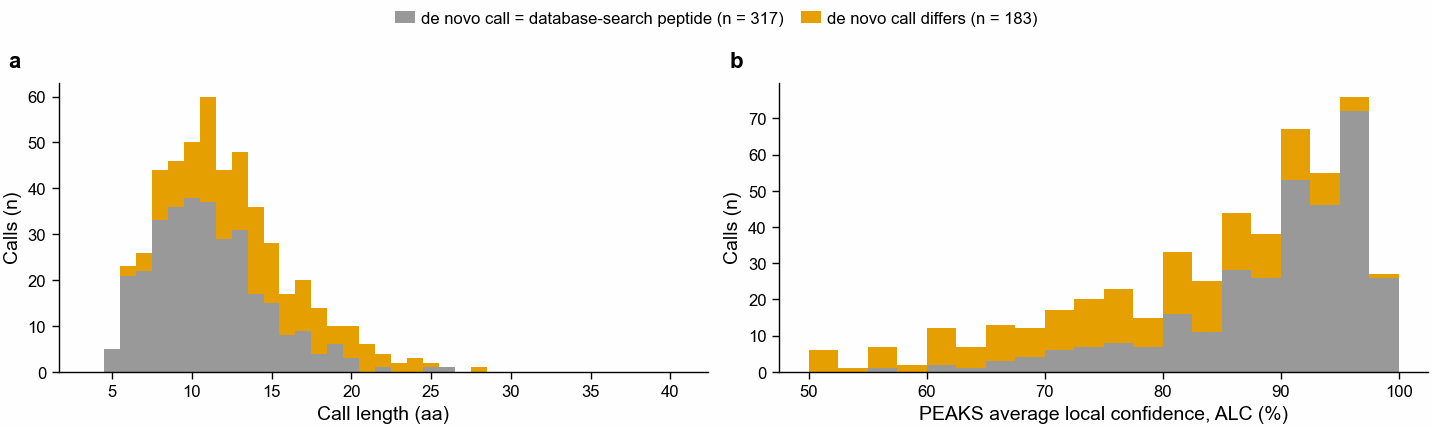

In [2]:
tab = (
    calls.group_by("split", "source_absent")
    .agg(
        pl.len().alias("n_calls"),
        pl.col("length").median().alias("median_length_aa"),
        pl.col("alc_percent").median().alias("median_alc_percent"),
        pl.col("denovo_equals_db_search")
        .mean()
        .round(3)
        .alias("fraction_denovo_equals_db_search"),
    )
    .sort("split", "source_absent")
)
print(tab)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2)
same = calls.filter(pl.col("denovo_equals_db_search"))
diff = calls.filter(~pl.col("denovo_equals_db_search"))
bins = np.arange(3.5, 41.5, 1)
axs[0].hist(
    [same["length"].to_list(), diff["length"].to_list()],
    bins=bins,
    stacked=True,
    color=[pf.GREY, pf.OKABE_ITO["orange"]],
    label=[
        f"de novo call = database-search peptide (n = {same.height})",
        f"de novo call differs (n = {diff.height})",
    ],
)
axs[0].set_xlabel("Call length (aa)")
axs[0].set_ylabel("Calls (n)")
bins = np.arange(50, 101, 2.5)
axs[1].hist(
    [same["alc_percent"].to_list(), diff["alc_percent"].to_list()],
    bins=bins,
    stacked=True,
    color=[pf.GREY, pf.OKABE_ITO["orange"]],
)
axs[1].set_xlabel("PEAKS average local confidence, ALC (%)")
axs[1].set_ylabel("Calls (n)")
pf.shared_legend(fig, ncol=2)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "354_frozen_calls_length_alc_PXD005280")

## 2. How often one k-mer matches by chance

Notebook 300's counting estimate, applied to this database: the expected number of places
in the 20,734 proteins where a k-mer of the database's own composition appears by chance is
(start positions) x Pr(same)^k, where Pr(same) is the chance two random database residues
fall in the same letter of the alphabet (the sum of squared letter frequencies). Fewer is
better for telling sources apart; one or more means a single k-mer seed cannot by itself
point to one protein.

shape: (4, 9)
┌────────────┬─────────┬─────────┬─────────────┬───┬───────────┬───────────┬──────────┬──────────┐
│ alphabet   ┆ letters ┆ pr_same ┆ 4           ┆ … ┆ 6         ┆ 7         ┆ 8        ┆ 9        │
│ ---        ┆ ---     ┆ ---     ┆ ---         ┆   ┆ ---       ┆ ---       ┆ ---      ┆ ---      │
│ str        ┆ i64     ┆ f64     ┆ f64         ┆   ┆ f64       ┆ f64       ┆ f64      ┆ f64      │
╞════════════╪═════════╪═════════╪═════════════╪═══╪═══════════╪═══════════╪══════════╪══════════╡
│ protein20  ┆ 20      ┆ 0.0596  ┆ 144.123939  ┆ … ┆ 0.510092  ┆ 0.030346  ┆ 0.001805 ┆ 0.000107 │
│ massspec18 ┆ 18      ┆ 0.0737  ┆ 336.609946  ┆ … ┆ 1.820686  ┆ 0.133902  ┆ 0.009848 ┆ 0.000724 │
│ hsdm17     ┆ 17      ┆ 0.0934  ┆ 867.960707  ┆ … ┆ 7.538671  ┆ 0.702571  ┆ 0.065476 ┆ 0.006102 │
│ sdm12      ┆ 12      ┆ 0.1405  ┆ 4446.741241 ┆ … ┆ 87.419334 ┆ 12.257114 ┆ 1.718571 ┆ 0.24096  │
└────────────┴─────────┴─────────┴─────────────┴───┴───────────┴───────────┴──────────┴────────

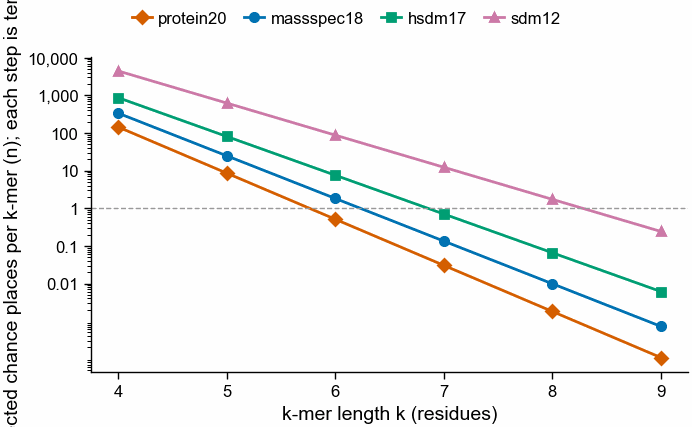

In [3]:
import gzip
import sys

sys.path.insert(0, "../nextflow-runs/fragment-source/bin")
from alphabets import CLUSTERS, class_of

seqs = []
with gzip.open(FROZEN / "db_full.fasta.gz", "rt") as fh:
    cur = []
    for line in fh:
        if line.startswith(">"):
            if cur:
                seqs.append("".join(cur))
            cur = []
        else:
            cur.append(line.strip())
    seqs.append("".join(cur))
letters = Counter("".join(seqs))
rows = []
for alphabet in ["protein20", "massspec18", "hsdm17", "sdm12"]:
    cls = class_of(alphabet)
    freq = Counter()
    for aa, n in letters.items():
        if aa in cls:
            freq[cls[aa]] += n
    tot = sum(freq.values())
    pr_same = sum((n / tot) ** 2 for n in freq.values())
    for k in range(4, 10):
        starts = sum(max(len(s) - k + 1, 0) for s in seqs)
        rows.append(
            {
                "alphabet": alphabet,
                "letters": len(CLUSTERS[alphabet]),
                "k": k,
                "pr_same": round(pr_same, 4),
                "expected_chance_places": starts * pr_same**k,
            }
        )
chance = pl.DataFrame(rows)
print(
    chance.pivot(
        on="k",
        index=["alphabet", "letters", "pr_same"],
        values="expected_chance_places",
    )
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
style = {
    "protein20": ("D", pf.OKABE_ITO["vermillion"]),
    "massspec18": ("o", pf.OKABE_ITO["blue"]),
    "hsdm17": ("s", pf.OKABE_ITO["bluish_green"]),
    "sdm12": ("^", pf.OKABE_ITO["reddish_purple"]),
}
for alphabet, (marker, colour) in style.items():
    d = chance.filter(pl.col("alphabet") == alphabet)
    ax.plot(
        d["k"], d["expected_chance_places"], marker=marker, color=colour, label=alphabet
    )
ax.axhline(1, color=pf.GREY, lw=0.5, ls="--")
ax.set_yscale("log")
ax.set_yticks([0.01, 0.1, 1, 10, 100, 1000, 10000])
ax.set_yticklabels(["0.01", "0.1", "1", "10", "100", "1,000", "10,000"])
ax.set_xlabel("k-mer length k (residues)")
ax.set_ylabel("Expected chance places per k-mer (n); each step is tenfold")
pf.shared_legend(fig, ncol=4)
pf.save(fig, FIG / "354_expected_chance_kmer_places_human_crap")

## 3. Development split: the k and alphabet that go to test

Each kmerseek setting was run on the 250 development calls and on 2,500 composition
shuffles of them. The threshold is the smallest check score at most 1% of shuffles reach;
recovery is the share of development calls with an accepted source in the top five at or
above it. Higher is better. The settings frozen for test are ringed. Development numbers
choose settings; they are not the result.

shape: (18, 7)
┌───────────────┬────────────┬─────┬─────┬──────────────┬────────────────────────┬──────────────────────┐
│ setting       ┆ alphabet   ┆ k   ┆ tau ┆ dev_recovery ┆ dev_median_list_length ┆ dev_shuffle_assigned │
│ ---           ┆ ---        ┆ --- ┆ --- ┆ ---          ┆ ---                    ┆ ---                  │
│ str           ┆ str        ┆ i64 ┆ i64 ┆ f64          ┆ f64                    ┆ f64                  │
╞═══════════════╪════════════╪═════╪═════╪══════════════╪════════════════════════╪══════════════════════╡
│ comparison    ┆ comparison ┆ 0   ┆ 66  ┆ 0.648        ┆ 1.0                    ┆ 0.0088               │
│ hsdm17_k4     ┆ hsdm17     ┆ 4   ┆ 68  ┆ 0.632        ┆ 1.0                    ┆ 0.008                │
│ hsdm17_k5     ┆ hsdm17     ┆ 5   ┆ 67  ┆ 0.644        ┆ 1.0                    ┆ 0.01                 │
│ hsdm17_k6     ┆ hsdm17     ┆ 6   ┆ 66  ┆ 0.652        ┆ 1.0                    ┆ 0.0084               │
│ hsdm17_k7     ┆ hsdm17     ┆ 

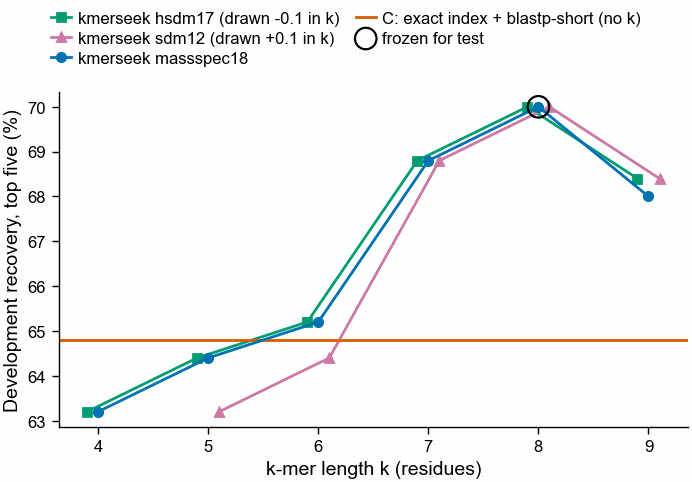

In [4]:
print(dev.sort("alphabet", "k"))
print(json.dumps(choice, indent=1))
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 62)
marks = {
    "massspec18": ("o", pf.OKABE_ITO["blue"]),
    "hsdm17": ("s", pf.OKABE_ITO["bluish_green"]),
    "sdm12": ("^", pf.OKABE_ITO["reddish_purple"]),
}
# The three alphabets give the same recovery at most k, so each is drawn 0.1 to one side of
# its k to keep all three visible; massspec18 sits at the true k and is drawn last.
offset = {"massspec18": 0.0, "hsdm17": -0.1, "sdm12": 0.1}
for alphabet in ["hsdm17", "sdm12", "massspec18"]:
    marker, colour = marks[alphabet]
    d = dev.filter(pl.col("alphabet") == alphabet).sort("k")
    ax.plot(
        d["k"] + offset[alphabet],
        d["dev_recovery"] * 100,
        marker=marker,
        color=colour,
        label=f"kmerseek {alphabet}"
        + (
            "" if alphabet == "massspec18" else f" (drawn {offset[alphabet]:+.1f} in k)"
        ),
        zorder=3 if alphabet == "massspec18" else 2,
    )
comp = dev.filter(pl.col("setting") == "comparison")
ax.axhline(
    comp["dev_recovery"][0] * 100,
    color=pf.OKABE_ITO["vermillion"],
    lw=1,
    label="C: exact index + blastp-short (no k)",
)
for s in choice["kmerseek_settings"]:
    r = dev.filter((pl.col("alphabet") == s["alphabet"]) & (pl.col("k") == s["k"]))
    ax.scatter(
        r["k"],
        r["dev_recovery"] * 100,
        s=60,
        facecolor="none",
        edgecolor="black",
        lw=0.8,
        label="frozen for test" if s is choice["kmerseek_settings"][0] else None,
        zorder=5,
    )
ax.set_xlabel("k-mer length k (residues)")
ax.set_ylabel("Development recovery, top five (%)")
ax.set_xticks(sorted(dev.filter(pl.col("k") > 0)["k"].unique()))
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / "354_dev_recovery_by_k_PXD005280")

## 4. Recovery against false assignment, test split

Each line is one workflow with its threshold swept from low to high. The x axis is the
share of the 50 source-absent calls that still get a confident source (lower is better);
the y axis is the share of the 200 source-present calls with an accepted source in the top
five (higher is better). The filled point is the threshold fixed on development. The pass
region is the top-left corner: recovery at least 95% (rule 1) and false assignment at most
1% (rule 2).

shape: (2, 4)
┌───────────────────────────────┬───────────┬───────────────┬──────────────────┐
│ method                        ┆ threshold ┆ recovery_top5 ┆ false_assignment │
│ ---                           ┆ ---       ┆ ---           ┆ ---              │
│ str                           ┆ i64       ┆ str           ┆ str              │
╞═══════════════════════════════╪═══════════╪═══════════════╪══════════════════╡
│ K: kmerseek massspec18, k = 8 ┆ 62        ┆ 140 of 200    ┆ 4 of 50          │
│ C: exact index + blastp-short ┆ 66        ┆ 128 of 200    ┆ 6 of 50          │
└───────────────────────────────┴───────────┴───────────────┴──────────────────┘


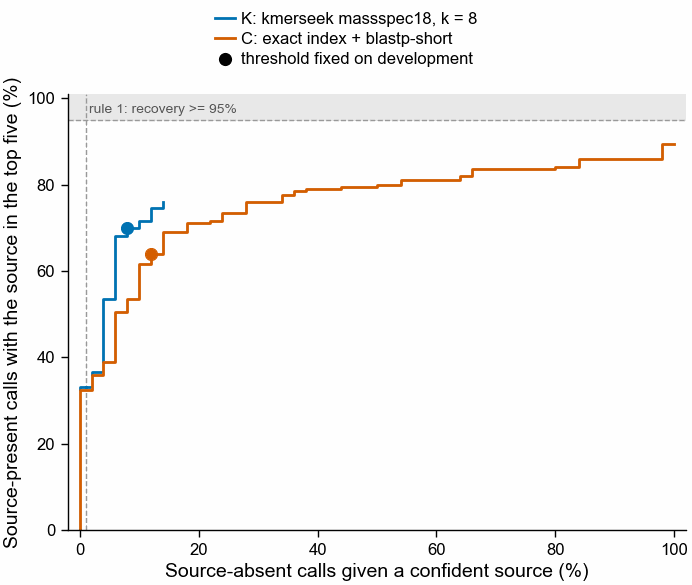

In [5]:
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 75)
ax.axhspan(95, 101, xmin=0, xmax=1, color="#e8e8e8", zorder=0)
ax.axhline(95, color=pf.GREY, lw=0.5, ls="--")
ax.axvline(1, color=pf.GREY, lw=0.5, ls="--")
ax.text(1.5, 96, "rule 1: recovery >= 95%", fontsize=5, color="#555555", va="bottom")
for name in METHODS:
    d = curve.filter(pl.col("method") == name).sort("false_assignment", "recovery")
    ax.step(
        d["false_assignment"] * 100,
        d["recovery"] * 100,
        where="post",
        color=COLOUR[name],
        label=LABEL[name],
    )
    mm = m["metrics"][name]
    ax.scatter(
        [mm["false_assignment"] * 100],
        [mm["recovery_top5"] * 100],
        color=COLOUR[name],
        s=18,
        zorder=5,
    )
ax.scatter([], [], color="black", s=18, label="threshold fixed on development")
ax.set_xlabel("Source-absent calls given a confident source (%)")
ax.set_ylabel("Source-present calls with the source in the top five (%)")
ax.set_xlim(-2, 102)
ax.set_ylim(0, 101)
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "354_recovery_vs_false_assignment_PXD005280")
rows = [
    {
        "method": LABEL[n],
        "threshold": m["metrics"][n]["tau"],
        "recovery_top5": f"{m['metrics'][n]['n_recovered']} of {m['metrics'][n]['n_present']}",
        "false_assignment": f"{m['metrics'][n]['n_false']} of {m['metrics'][n]['n_absent']}",
    }
    for n in METHODS
]
print(pl.DataFrame(rows))

### Where kmerseek's extra recoveries come from

Both workflows score candidates with the same check, so a call kmerseek recovers and C does
not must differ in which candidates were sent or in the threshold. The table lists the
source-present calls recovered by one workflow only, with the check score of the accepted
source under each (empty: not among the candidates).

thresholds: K: kmerseek massspec18, k = 8 62, C: exact index + blastp-short 66
shape: (18, 8)
┌───────────┬──────────────────────────┬──────────────────────────┬───────────────────────────┬─────────────────────────┬──────────────────────┬───────────────────────────┬───────────────────────────┐
│ call_id   ┆ peptide                  ┆ db_search_peptide        ┆ accepted_in_db            ┆ recovered_massspec18_k8 ┆ recovered_comparison ┆ accepted_score_massspec18 ┆ accepted_score_comparison │
│ ---       ┆ ---                      ┆ ---                      ┆ ---                       ┆ ---                     ┆ ---                  ┆ _k8                       ┆ ---                       │
│ str       ┆ str                      ┆ str                      ┆ str                       ┆ bool                    ┆ bool                 ┆ ---                       ┆ i64                       │
│           ┆                          ┆                          ┆                           ┆       

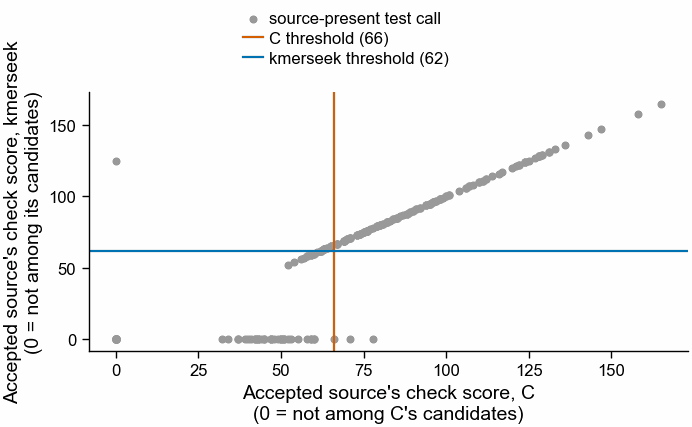

In [6]:
wide = per_call.filter(pl.col("case") == "present").pivot(
    on="method",
    index="call_id",
    values=["recovered", "accepted_score", "list_length"],
    aggregate_function="first",
)
k0 = KMERSEEK[0]
only = wide.filter(pl.col(f"recovered_{k0}") != pl.col("recovered_comparison")).join(
    calls.select("call_id", "peptide", "db_search_peptide", "accepted_in_db"),
    on="call_id",
)
print(
    f"thresholds: {LABEL[k0]} {m['metrics'][k0]['tau']}, {LABEL['comparison']} {m['metrics']['comparison']['tau']}"
)
print(
    only.select(
        "call_id",
        "peptide",
        "db_search_peptide",
        "accepted_in_db",
        f"recovered_{k0}",
        "recovered_comparison",
        f"accepted_score_{k0}",
        "accepted_score_comparison",
    ).sort(f"recovered_{k0}", f"accepted_score_{k0}")
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
both = wide.with_columns(
    pl.col(f"accepted_score_{k0}").fill_null(0),
    pl.col("accepted_score_comparison").fill_null(0),
)
ax.scatter(
    both["accepted_score_comparison"],
    both[f"accepted_score_{k0}"],
    s=6,
    color=pf.GREY,
    label="source-present test call",
)
ax.axvline(
    m["metrics"]["comparison"]["tau"],
    color=COLOUR["comparison"],
    lw=0.8,
    label=f"C threshold ({m['metrics']['comparison']['tau']})",
)
ax.axhline(
    m["metrics"][k0]["tau"],
    color=COLOUR[k0],
    lw=0.8,
    label=f"kmerseek threshold ({m['metrics'][k0]['tau']})",
)
ax.set_xlabel("Accepted source's check score, C\n(0 = not among C's candidates)")
ax.set_ylabel("Accepted source's check score, kmerseek\n(0 = not among its candidates)")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "354_accepted_source_score_kmerseek_vs_comparison_PXD005280")

## 5. Candidate-list length

The candidate list is every candidate whose check score reaches the method's threshold. A
shorter list is better (rule 3: median at most five). The dashed lines are the candidates
each workflow sent to the check, before the threshold.

shape: (2, 4)
┌───────────────┬────────────────────┬─────────────────┬──────────────────────┐
│ method        ┆ median_list_length ┆ max_list_length ┆ median_sent_to_check │
│ ---           ┆ ---                ┆ ---             ┆ ---                  │
│ str           ┆ f64                ┆ i64             ┆ f64                  │
╞═══════════════╪════════════════════╪═════════════════╪══════════════════════╡
│ comparison    ┆ 1.0                ┆ 14              ┆ 221.0                │
│ massspec18_k8 ┆ 1.0                ┆ 16              ┆ 1.0                  │
└───────────────┴────────────────────┴─────────────────┴──────────────────────┘


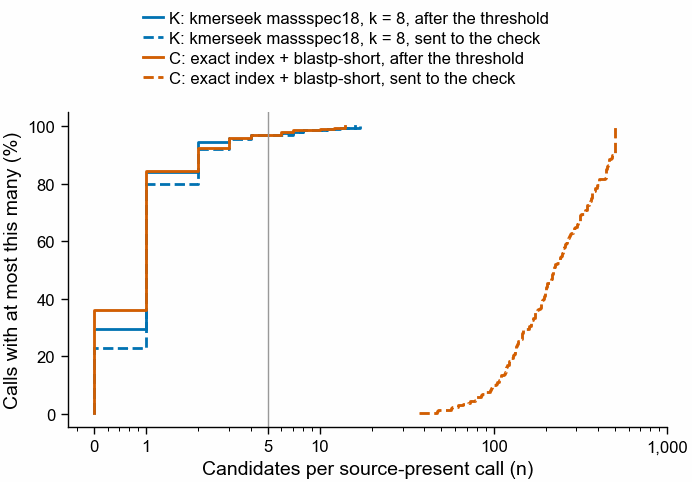

In [7]:
pc = per_call.filter(pl.col("case") == "present")
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 62)
for name in METHODS:
    d = pc.filter(pl.col("method") == name)
    for col, ls, suffix in (
        ("list_length", "-", "after the threshold"),
        ("n_candidates_before_check", "--", "sent to the check"),
    ):
        x = np.sort(np.asarray(d[col].to_list(), dtype=float))
        y = np.arange(1, len(x) + 1) / len(x) * 100
        ax.step(
            np.maximum(x, 0.5),
            y,
            where="post",
            color=COLOUR[name],
            ls=ls,
            label=f"{LABEL[name]}, {suffix}",
        )
ax.axvline(5, color=pf.GREY, lw=0.5)
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 5, 10, 100, 1000])
ax.set_xticklabels(["0", "1", "5", "10", "100", "1,000"])
ax.set_xlabel("Candidates per source-present call (n)")
ax.set_ylabel("Calls with at most this many (%)")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "354_candidate_list_length_PXD005280")
print(
    pc.group_by("method")
    .agg(
        pl.col("list_length").median().alias("median_list_length"),
        pl.col("list_length").max().alias("max_list_length"),
        pl.col("n_candidates_before_check").median().alias("median_sent_to_check"),
    )
    .sort("method")
)

## 6. Runtime, end to end

One CPU, the 250 test calls against the full database, from a fresh index build. Build is
kmerseek's index (K) or the exact 5-mer index plus `makeblastdb` (C); search is kmerseek's
search (K) or the exact lookup plus blastp-short (C); verify is the shared full-alphabet
check. Shorter is better (rule 4b asks for C's total to be at least five times K's).

shape: (6, 4)
┌───────────────┬────────┬────────────┬───────────┐
│ method        ┆ step   ┆ wall_s     ┆ cpu_s     │
│ ---           ┆ ---    ┆ ---        ┆ ---       │
│ str           ┆ str    ┆ f64        ┆ f64       │
╞═══════════════╪════════╪════════════╪═══════════╡
│ comparison    ┆ build  ┆ 14.087782  ┆ 13.762552 │
│ comparison    ┆ search ┆ 109.071914 ┆ 108.8449  │
│ comparison    ┆ verify ┆ 1.341188   ┆ 1.341096  │
│ massspec18_k8 ┆ build  ┆ 18.703311  ┆ 15.661292 │
│ massspec18_k8 ┆ search ┆ 8.266829   ┆ 7.026754  │
│ massspec18_k8 ┆ verify ┆ 0.00712    ┆ 0.00712   │
└───────────────┴────────┴────────────┴───────────┘


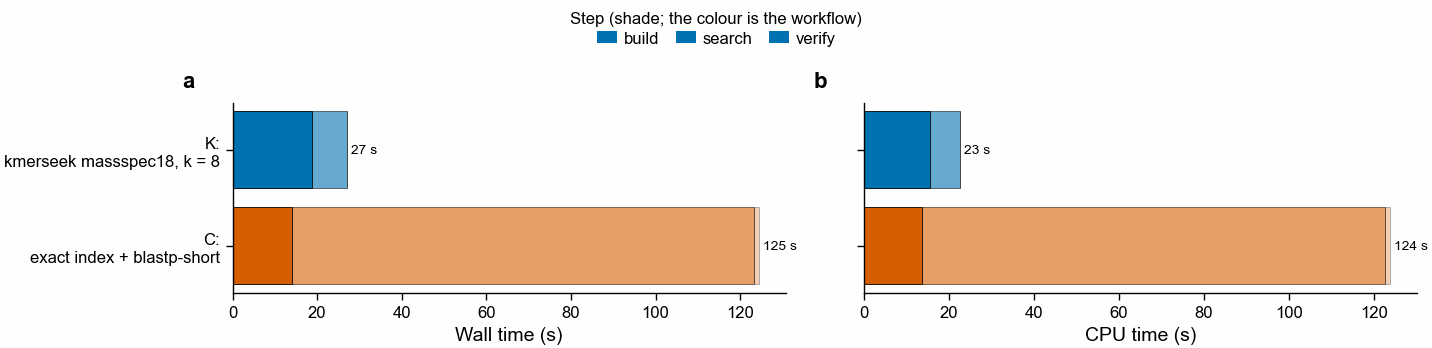

In [8]:
print(runtime.sort("method", "step"))
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 45, ncols=2)
steps = ["build", "search", "verify"]
shade = {"build": 1.0, "search": 0.6, "verify": 0.3}
for ax, col, xlabel in (
    (axs[0], "wall_s", "Wall time (s)"),
    (axs[1], "cpu_s", "CPU time (s)"),
):
    for i, name in enumerate(METHODS):
        left = 0.0
        for st in steps:
            v = runtime.filter((pl.col("method") == name) & (pl.col("step") == st))[col]
            v = float(v[0]) if len(v) else 0.0
            ax.barh(
                i,
                v,
                left=left,
                color=COLOUR[name],
                alpha=shade[st],
                edgecolor="black",
                lw=0.3,
            )
            left += v
        ax.text(left, i, f" {left:,.0f} s", va="center", fontsize=5)
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels([LABEL[n].replace(": ", ":\n") for n in METHODS])
    ax.set_xlabel(xlabel)
    ax.invert_yaxis()
axs[1].set_yticklabels([])
for (
    st
) in steps:  # legend proxies in grey: the shade is the step, the colour the workflow
    axs[0].barh(
        [], [], color="black", alpha=shade[st], edgecolor="black", lw=0.3, label=st
    )
pf.shared_legend(fig, ncol=3, title="Step (shade; the colour is the workflow)")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "354_runtime_build_search_verify_PXD005280")

## 7. Shuffled controls

Five composition shuffles and five shuffles keeping adjacent residue pairs of each test
call, searched against the full database. Each bar is the share given a confident source at
the method's fixed threshold. A shuffle has no source, so lower is better; the thresholds
were set to allow 1% on development composition shuffles.

shape: (4, 3)
┌───────────────────────────────┬───────────────────────┬──────────────────┐
│ method                        ┆ control               ┆ assigned_percent │
│ ---                           ┆ ---                   ┆ ---              │
│ str                           ┆ str                   ┆ f64              │
╞═══════════════════════════════╪═══════════════════════╪══════════════════╡
│ K: kmerseek massspec18, k = 8 ┆ composition shuffle   ┆ 1.04             │
│ K: kmerseek massspec18, k = 8 ┆ adjacent-pair shuffle ┆ 33.6             │
│ C: exact index + blastp-short ┆ composition shuffle   ┆ 1.52             │
│ C: exact index + blastp-short ┆ adjacent-pair shuffle ┆ 35.6             │
└───────────────────────────────┴───────────────────────┴──────────────────┘
composition shuffles identical to the call itself: 0 of 1250
adjacent-pair shuffles identical to the call itself: 566 of 1250


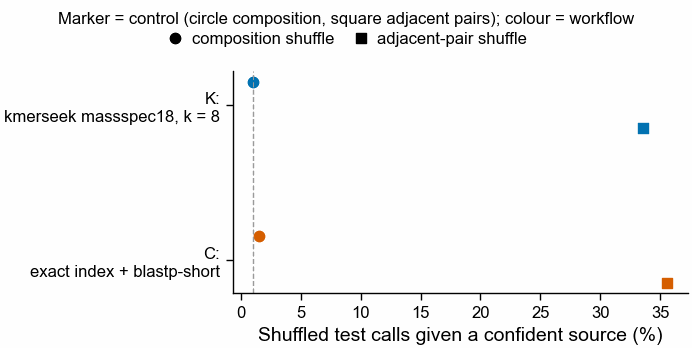

In [9]:
rows = []
for name in METHODS:
    mm = m["metrics"][name]
    rows += [
        {
            "method": LABEL[name],
            "control": "composition shuffle",
            "assigned_percent": mm["control_assigned_composition"] * 100,
        },
        {
            "method": LABEL[name],
            "control": "adjacent-pair shuffle",
            "assigned_percent": mm["control_assigned_dipeptide"] * 100,
        },
    ]
ctrl = pl.DataFrame(rows)
print(ctrl)


# A short peptide has few orders that keep every adjacent pair, often only its own.
def read_fa(path):
    out, name = {}, None
    for line in open(path):
        if line.startswith(">"):
            name = line[1:].strip()
        else:
            out[name] = line.strip()
    return out


ctrl_seqs = read_fa(FROZEN / "queries_test_controls.fasta")
orig = dict(zip(calls["call_id"], calls["peptide"]))
same = Counter()
for q, s in ctrl_seqs.items():
    cid, kind = q.rsplit("_", 1)
    same[(kind.rstrip("0123456789"), s == orig[cid])] += 1
for kind in ("comp", "dipep"):
    n_same, n = same[(kind, True)], same[(kind, True)] + same[(kind, False)]
    print(
        f"{'composition' if kind == 'comp' else 'adjacent-pair'} shuffles identical to the call itself: {n_same} of {n}"
    )
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
for j, kind in enumerate(["composition shuffle", "adjacent-pair shuffle"]):
    for i, name in enumerate(METHODS):
        v = ctrl.filter(
            (pl.col("method") == LABEL[name]) & (pl.col("control") == kind)
        )["assigned_percent"][0]
        ax.scatter(
            v,
            i + (0.15 if j else -0.15),
            marker="o" if j == 0 else "s",
            color=COLOUR[name],
            s=14,
        )
    ax.scatter([], [], marker="o" if j == 0 else "s", color="black", s=14, label=kind)
ax.axvline(1, color=pf.GREY, lw=0.5, ls="--")
ax.set_yticks(range(len(METHODS)))
ax.set_yticklabels([LABEL[n].replace(": ", ":\n") for n in METHODS])
ax.invert_yaxis()
ax.set_xlabel("Shuffled test calls given a confident source (%)")
pf.shared_legend(
    fig,
    ncol=2,
    title="Marker = control (circle composition, square adjacent pairs); colour = workflow",
)
pf.save(fig, FIG / "354_shuffled_controls_PXD005280")

## 8. Examples, residue by residue

One call per outcome, picked by a fixed rule: the lowest scan number in each group.
Each pair shows the call, the matched stretch of the protein with 1-based coordinates, the
match line (`|` same residue, `:` I against L or Q against K, blank otherwise, `-` a gap) and
how many aligned columns hold the same residue.

In [10]:
def show(call_id, target, pair, method=""):
    a = aln.filter(
        (pl.col("call_id") == call_id)
        & (pl.col("target") == target)
        & (pl.col("pair") == pair)
        & (pl.col("method").fill_null("") == method)
    ).row(0, named=True)
    c = calls.filter(pl.col("call_id") == call_id).row(0, named=True)
    w = max(len(target), 8)
    print(f"  {'call':<{w}} {a['query_start']:>5} {a['query_line']} {a['query_end']}")
    print(f"  {'':<{w}} {'':>5} {a['match_line']}")
    print(
        f"  {target:<{w}} {a['target_start']:>5} {a['target_line']} {a['target_end']}"
    )
    print(
        f"  {a['n_identical']} of {a['n_columns']} identical; check score {a['score']}"
    )


def describe(call_id):
    c = calls.filter(pl.col("call_id") == call_id).row(0, named=True)
    print(
        f"{call_id}: de novo call {c['peptide']} ({c['length']} aa, ALC {c['alc_percent']:.0f}%, "
        f"local confidence {c['local_confidence_percent']}); database search read {c['db_search_peptide']}; "
        f"accepted source {c['accepted_in_db']}"
    )


pcw = per_call.pivot(
    on="method",
    index=["call_id", "case"],
    values="recovered",
    aggregate_function="first",
)
k0 = KMERSEEK[0]
groups = {
    "found by kmerseek and by C": (pl.col(k0) == True) & (pl.col("comparison") == True),
    "found by kmerseek only": (pl.col(k0) == True) & (pl.col("comparison") == False),
    "found by C only": (pl.col(k0) == False) & (pl.col("comparison") == True),
    "found by neither": (pl.col(k0) == False) & (pl.col("comparison") == False),
}
present_ids = pcw.filter(pl.col("case") == "present")
for title, cond in groups.items():
    sel = (
        present_ids.filter(cond)
        .with_columns(
            pl.col("call_id").str.replace("scan", "").cast(pl.Int64).alias("scan")
        )
        .sort("scan")
    )
    print(f"\n=== {title}: {sel.height} of {present_ids.height} source-present calls")
    if sel.height == 0:
        continue
    cid = sel["call_id"][0]
    describe(cid)
    acc = sorted(
        calls.filter(pl.col("call_id") == cid)["accepted_in_db"][0].split(";")
    )[0]
    print(" against its accepted source:")
    show(cid, acc, "accepted source")
    for name in METHODS:
        top = aln.filter(
            (pl.col("call_id") == cid)
            & (pl.col("method") == name)
            & (pl.col("pair") == "top candidate")
        )
        if top.height:
            print(f" {LABEL[name]}, top candidate:")
            show(cid, top["target"][0], "top candidate", name)
        else:
            print(f" {LABEL[name]}: no candidate")

pa = per_call.filter((pl.col("case") == "absent"))
for name in METHODS:
    sel = (
        pa.filter((pl.col("method") == name) & (pl.col("confident") == True))
        .with_columns(
            pl.col("call_id").str.replace("scan", "").cast(pl.Int64).alias("scan")
        )
        .sort("scan")
    )
    print(
        f"\n=== source-absent calls given a confident source by {LABEL[name]}: {sel.height} of {pa.filter(pl.col('method') == name).height}"
    )
    if sel.height:
        cid = sel["call_id"][0]
        describe(cid)
        show(cid, sel["top_target"][0], "top candidate", name)


=== found by kmerseek and by C: 125 of 200 source-present calls
scan862: de novo call VKVDPSHDASK (11 aa, ALC 88%, local confidence 67 77 86 97 93 95 88 94 86 95 100); database search read VKVDPSHDASK; accepted source O75369
 against its accepted source:
  call         1 VKVDPSHDASK 11
                 |||||||||||
  O75369     837 VKVDPSHDASK 847
  11 of 11 identical; check score 79


 K: kmerseek massspec18, k = 8, top candidate:
  call         1 VKVDPSHDASK 11
                 |||||||||||
  O75369     837 VKVDPSHDASK 847
  11 of 11 identical; check score 79
 C: exact index + blastp-short, top candidate:
  call         1 VKVDPSHDASK 11
                 |||||||||||
  O75369     837 VKVDPSHDASK 847
  11 of 11 identical; check score 79

=== found by kmerseek only: 15 of 200 source-present calls
scan3384: de novo call KTTELSEMNR (10 aa, ALC 75%, local confidence 67 81 99 99 96 82 85 17 31 91); database search read TKTEISEMNR; accepted source P05787
 against its accepted source:
  call         3 TELSEMNR 10
                 ||:|||||
  P05787     305 TEISEMNR 312
  7 of 8 identical; check score 63
 K: kmerseek massspec18, k = 8, top candidate:
  call         3 TELSEMNR 10
                 ||:|||||
  P05787     305 TEISEMNR 312
  7 of 8 identical; check score 63
 C: exact index + blastp-short, top candidate:
  call         3 TELSEMNR 10
                 ||:|||||
  P05787 

## 9. Compute used

Every SLURM job of this notebook (`make cost`), including the download, the kmerseek build
and the trial runs. CPU-hours are allocated cores x elapsed time; the budget was two
compute-days.

shape: (15, 7)
┌──────────┬─────────────────┬─────────────────────┬───────┬──────────┬─────────────────────┬────────────────┐
│ JobID    ┆ JobName         ┆ State               ┆ NCPUS ┆ Elapsed  ┆ allocated_cpu_hours ┆ used_cpu_hours │
│ ---      ┆ ---             ┆ ---                 ┆ ---   ┆ ---      ┆ ---                 ┆ ---            │
│ i64      ┆ str             ┆ str                 ┆ i64   ┆ str      ┆ f64                 ┆ f64            │
╞══════════╪═════════════════╪═════════════════════╪═══════╪══════════╪═════════════════════╪════════════════╡
│ 48678939 ┆ nb354-download  ┆ COMPLETED           ┆ 1     ┆ 00:08:11 ┆ 0.136389            ┆ 0.002681       │
│ 48678977 ┆ nb354-build     ┆ FAILED              ┆ 8     ┆ 00:00:45 ┆ 0.1                 ┆ 0.044053       │
│ 48679441 ┆ nb354-build     ┆ CANCELLED by 363520 ┆ 0     ┆ 00:00:00 ┆ 0.0                 ┆ 0.0            │
│ 48679463 ┆ nb354-build     ┆ FAILED              ┆ 8     ┆ 00:00:29 ┆ 0.064444            ┆ 0.0

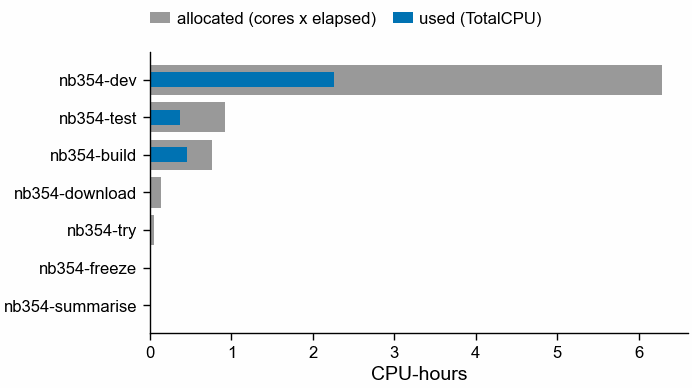

In [11]:
cost = compute.with_columns(
    pl.col("ElapsedRaw").cast(pl.Float64).alias("elapsed_s"),
    pl.col("NCPUS").cast(pl.Int64),
)
cost = cost.with_columns(
    (pl.col("elapsed_s") * pl.col("NCPUS") / 3600).alias("allocated_cpu_hours"),
    (pl.col("used_cpu_s") / 3600).alias("used_cpu_hours"),
)
print(
    cost.select(
        "JobID",
        "JobName",
        "State",
        "NCPUS",
        "Elapsed",
        "allocated_cpu_hours",
        "used_cpu_hours",
    )
)
tot = cost.select(
    pl.col("allocated_cpu_hours").sum(),
    pl.col("used_cpu_hours").sum(),
    (pl.col("elapsed_s").sum() / 3600).alias("elapsed_hours_summed_over_jobs"),
)
print(tot)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 50)
by = (
    cost.group_by("JobName")
    .agg(pl.col("allocated_cpu_hours").sum(), pl.col("used_cpu_hours").sum())
    .sort("allocated_cpu_hours")
)
ax.barh(
    by["JobName"],
    by["allocated_cpu_hours"],
    color=pf.GREY,
    label="allocated (cores x elapsed)",
)
ax.barh(
    by["JobName"],
    by["used_cpu_hours"],
    color=pf.OKABE_ITO["blue"],
    height=0.4,
    label="used (TotalCPU)",
)
ax.set_xlabel("CPU-hours")
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / "354_compute_cpu_hours")

## 10. Pass rule, applied

In [12]:
for name, v in m["per_setting"].items():
    print(f"{LABEL[name]}: {'PASS' if v['pass'] else 'FAIL'}")
    for rule, r in v["rules"].items():
        print(
            f"  {rule}: value {r['value']}, needed {r['needed']}, holds {r['holds']}"
            + (
                f" (C's recovery at false rate <= {r['false_rate']}: {r['comparison_recovery_at_same_false_rate']})"
                if "false_rate" in r
                else ""
            )
            + (
                f" (matched recovery: {r['matched_recovery']})"
                if "matched_recovery" in r
                else ""
            )
        )
print("\nVerdict:", m["verdict"])
print("Diagnostics:", json.dumps(m["diagnostics"], indent=1))

K: kmerseek massspec18, k = 8: FAIL
  rule1_recovery: value 0.7, needed 0.95, holds False
  rule2_false_assignment: value 0.08, needed 0.01, holds False
  rule3_median_list: value 1.0, needed 5, holds True
  rule4a_recovery_gain: value 0.16499999999999992, needed 0.1, holds True (C's recovery at false rate <= 0.08: 0.535)
  rule4b_speedup: value 4.615030913302521, needed 5.0, holds False (matched recovery: True)

Verdict: FAIL
Diagnostics: {
 "absent_calls_with_exact_peptide_in_another_protein": 1,
 "present_calls_with_exact_peptide_in_accepted_source": 119,
 "present_calls_denovo_equals_db_search": 119,
 "n_present": 200,
 "n_absent": 50
}


## Second reader: held / failed

A fresh agent session, given only the branch at cdf6415d and the Sherlock run folder, tried
to disprove each claim with its own scripts (read-only). It recomputed every headline number
from the per-run `scores.tsv` files, `calls.tsv` and `db_full.fasta.gz`. Its result: the FAIL
holds, and nothing it found changes the verdict or the explanation.

| Claim | Result | What it found |
|---|---|---|
| 1. Rule committed before any method ran | partly held | Rule commit 3743f18a at 14:35; dev job started 14:37; sdm12 k=4 stop committed 15:20, before the first dev table (15:25). But a smoke test (job 48680816, 14:27) ran kmerseek on 10 dev calls of an earlier freeze, none of them among the final 500, and computed no score. Fair wording: "before any method ran on the frozen calls". |
| 2. 500 calls, 250/250, 50 absent, 59 removed, 20,734 proteins, no shared protein | held | All counts reproduced. |
| 3. PEAKS-to-PD join on the precursor | held, as far as testable | All 500 mass-consistent (433 equal; the rest differ by +57, +16 or +114 Da of modifications). 7 pairs share 3 or fewer residues; wrong pairing or wrong de novo read cannot be told apart. |
| 4. massspec18 k=8 chosen correctly | held | Unique maximum 0.70; hsdm17 and sdm12 tie at k=8, so not sent to test. |
| 5. Recovery 140/200 (K), 128/200 (C) | held | |
| 6. False assignment 4/50 (K), 6/50 (C) | held | Absent runs used the reduced database: no removed accession in their output. |
| 7. Median list 1 and 1; sent to check 1 and 221 | held | |
| 8. Rule 4a: C's 53.5% at <= 8%, +16.5 points | held | C reaches it at threshold 74. |
| 9. Rule 4b: 125 s vs 27 s, 4.6x, one thread, fresh builds | held | Single timing run each, so 4.6x against 5x is close. |
| 10. Lead is a threshold effect | held | Whenever both send the source to the check they give it the same score. |
| 11. massspec18 8-mer = full-alphabet 8-mer with I=L, Q=K | held | Brute-force normalised 8-mer search gives kmerseek's candidate sets. |
| 12. 566/1,250 adjacent-pair shuffles identical; 33.6% / 35.6%; 1.04% / 1.52% | held | |
| 13. Threshold rule | held | Brute-force scan matches every setting. |
| 14. Compute 8.2 / 3.1 CPU-h, 1.2 h, 14:07-15:36 | held | Login-node and laptop work before 14:07 is not counted. |
| 15. Same check and normalisation for both | held | |
| 16. Printed alignments | held | All 739 rows of `alignments.tsv` agree with the database. |

Other problems it raised, none changing the numbers:

1. The accepted-source set is Proteome Discoverer's 2015 protein list, matched by accession.
   In 51 of 500 calls another protein in the frozen database also holds the database-search
   peptide but does not count as correct. Counting those too leaves recovery at 140 and 128.
2. kmerseek reports only one accession for proteins with identical sequences (20,650 targets
   at k=8 for 20,734 proteins). No recovery was lost here.
3. 22 of the 200 source-present test calls are shorter than 8 residues, so kmerseek at k=8
   cannot find them; the pre-registration counts them as abstentions.
4. Rule 4b rests on one timing run per workflow; the verdict does not depend on it.